# Phase 4 — Addition 2: Active Learning Adaptation Workflow

- **Budget** B = 50 labels from a 1,000-image candidate pool (seeded subset of train)
- **Acquisition**: uncertainty = margin (top1 − top2 detection confidence @ conf=0.001, no detection → 0);
  baseline = seeded random batch from the same pool
- **Unseen condition**: synthetic turbidity (blur + noise + brightness/contrast drop) applied to all 682
  test images (geometry unchanged → labels valid); original test kept as the retention set
- **Fine-tune**: 15 epochs each from `models/best.pt` (read-only) → `runs/{uncertainty,random}/`
- Group integrity: pool ⊂ train, test derivatives stay in test — no train/test leakage

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display

OUT = Path('active_learning_v1')
idx = json.loads((OUT / 'active_learning_indices.json').read_text())
cmp = json.loads((OUT / 'comparison.json').read_text())

print(f"Budget B = {idx['budget']} | pool = {idx['pool_size']} | {idx['acquisition']}")
rows = []
for method, conds in cmp['results'].items():
    for cond, m in conds.items():
        rows.append({'checkpoint': method, 'condition': cond, 'P': m['precision'],
                     'R': m['recall'], 'mAP50': m['mAP50'], 'mAP50-95': m['mAP50-95']})
display(pd.DataFrame(rows).sort_values(['condition', 'checkpoint']).reset_index(drop=True))
print()
print('New-condition d_mAP50 (turbid):', cmp['delta_mAP50_turbid'])
print('Retention d_mAP50 (clean):     ', cmp['retention_delta_mAP50_clean'])

Budget B = 50 | pool = 1000 | margin (top1 - top2 detection conf, conf=0.001; none -> 0)


,checkpoint,condition,P,R,mAP50,mAP50-95
0,original,clean,0.8188,0.8060,0.8367,0.4822
1,random,clean,0.8198,0.7629,0.8058,0.4383
2,uncertainty,clean,0.8217,0.8083,0.8354,0.4824
3,original,turbid,0.5464,0.3098,0.3190,0.1367
4,random,turbid,0.5847,0.2924,0.3043,0.1193
5,uncertainty,turbid,0.5206,0.3139,0.3193,0.1369



New-condition d_mAP50 (turbid): {'uncertainty': 0.0003, 'random': -0.0147}
Retention d_mAP50 (clean):      {'uncertainty': -0.0013, 'random': -0.0309}


=== confusion matrices: turbid (before = original, after = fine-tuned) ===
-- original --


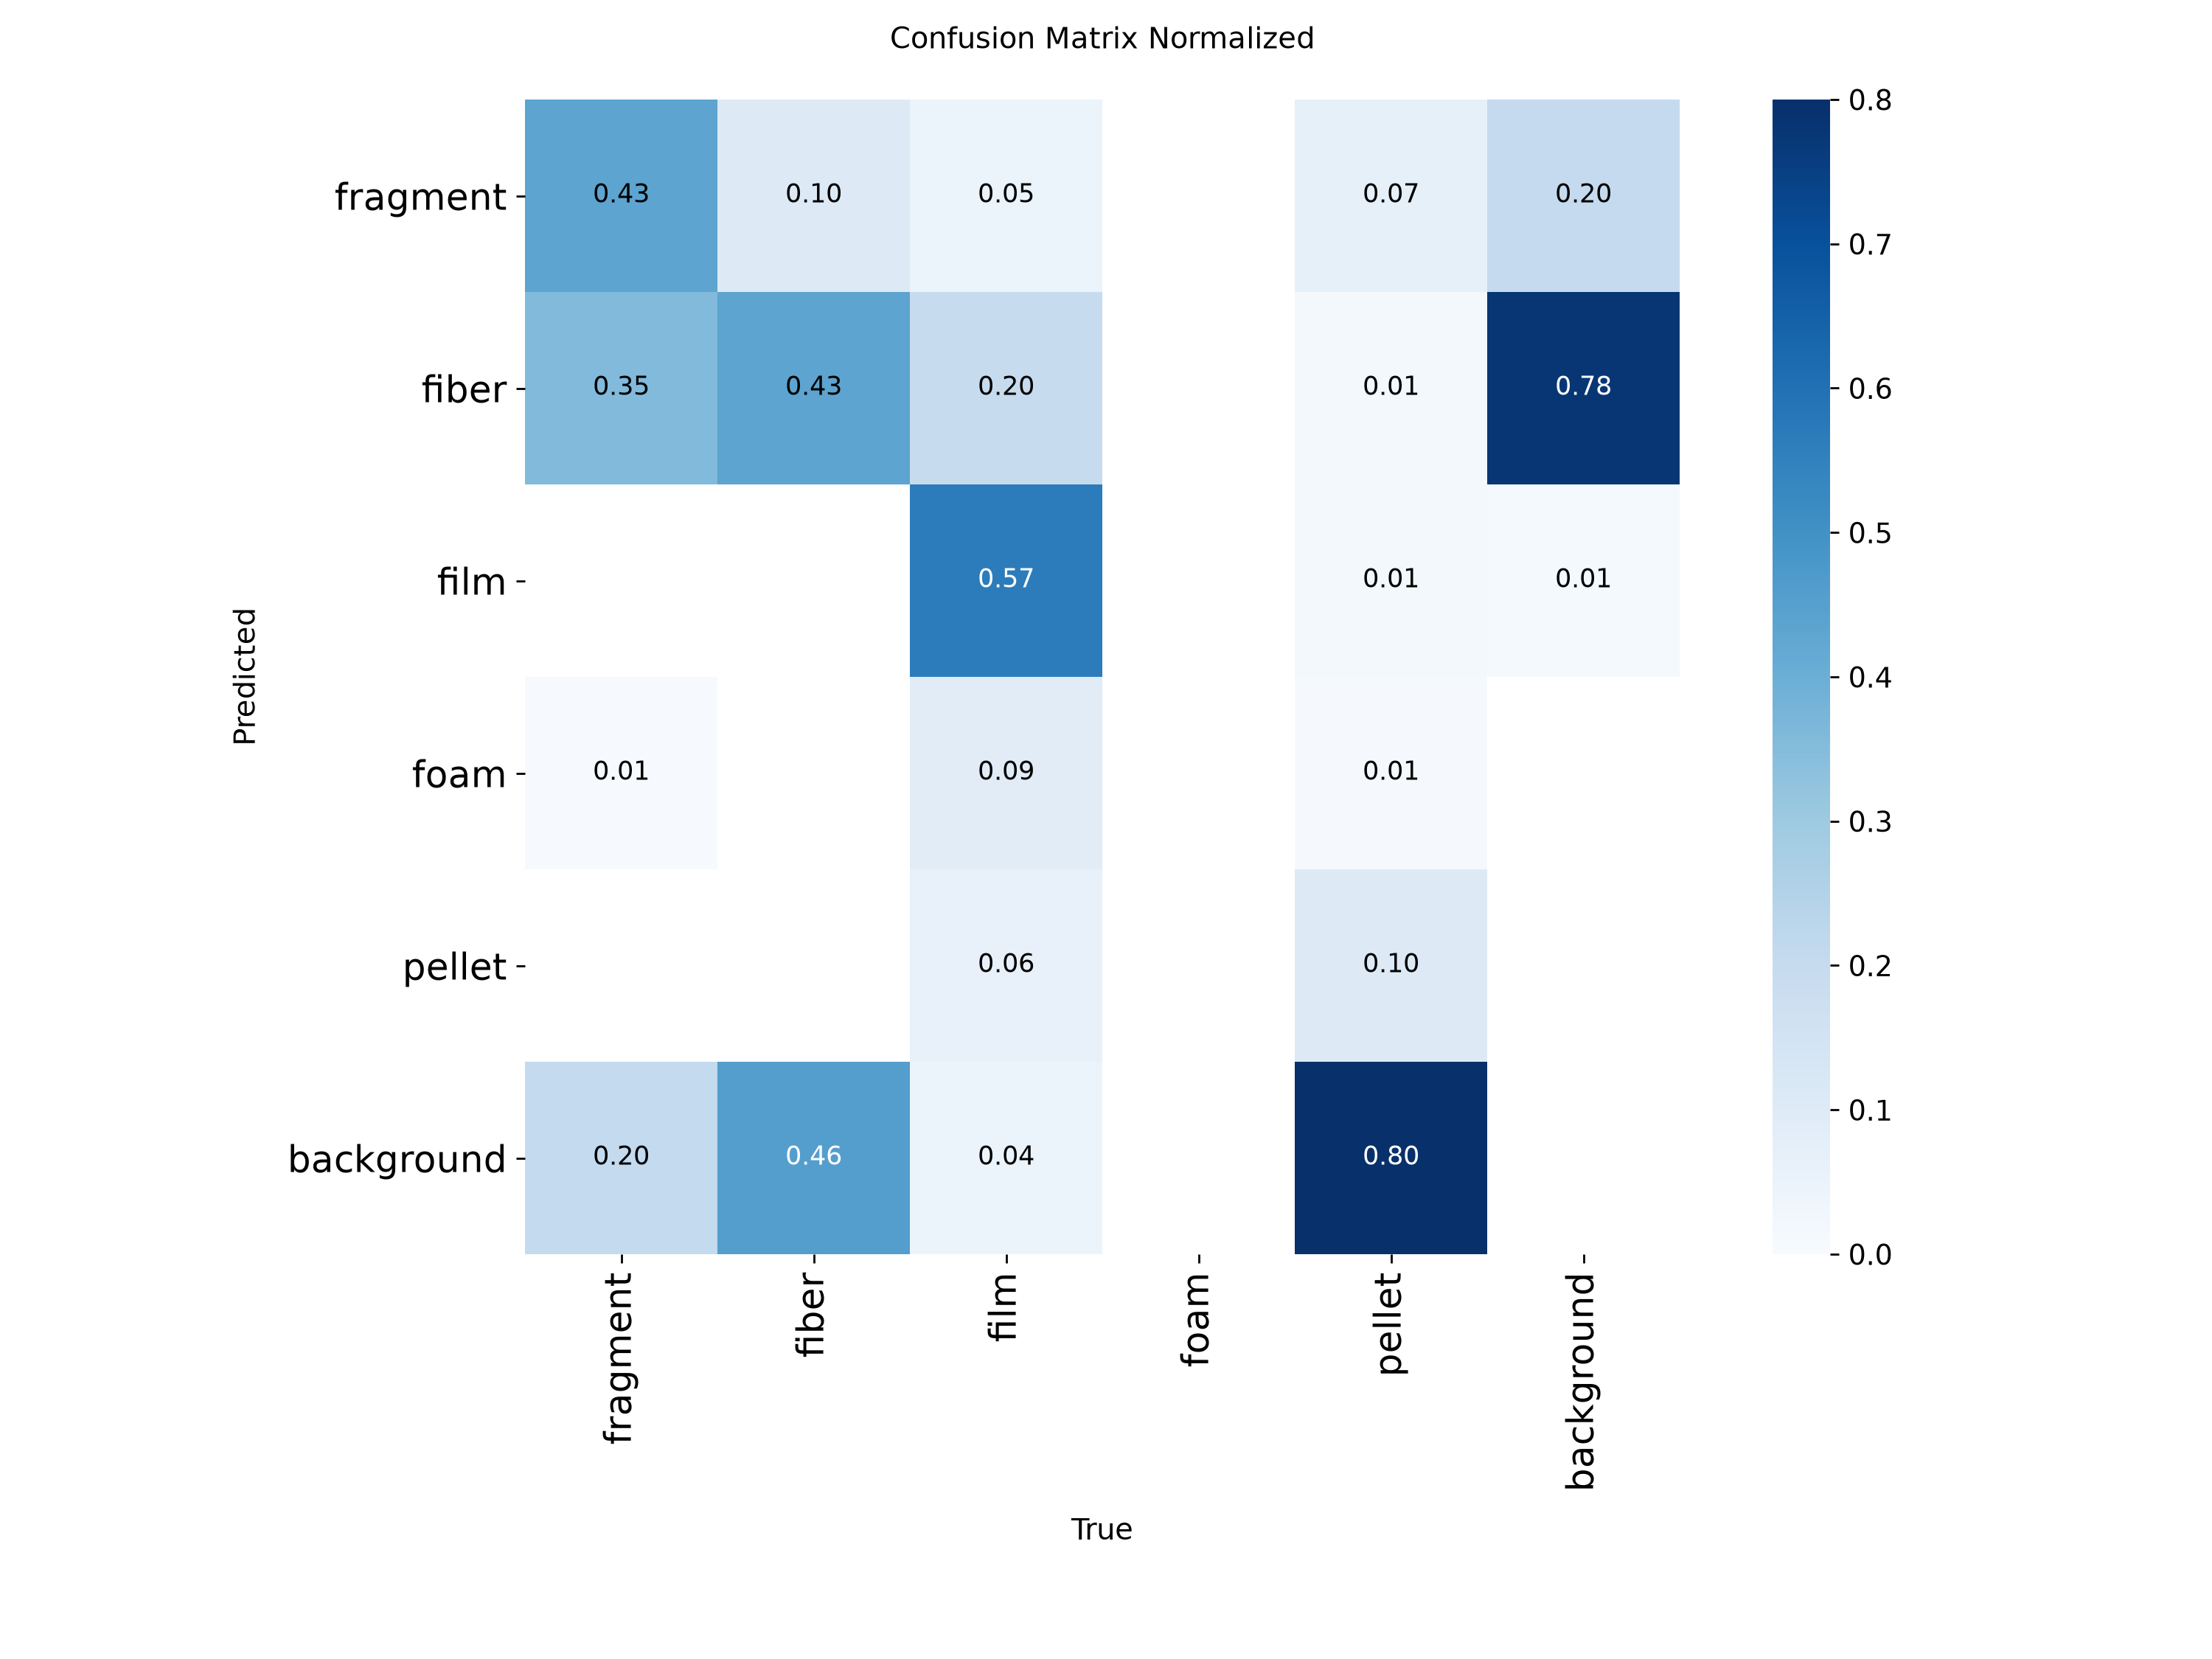

-- uncertainty --


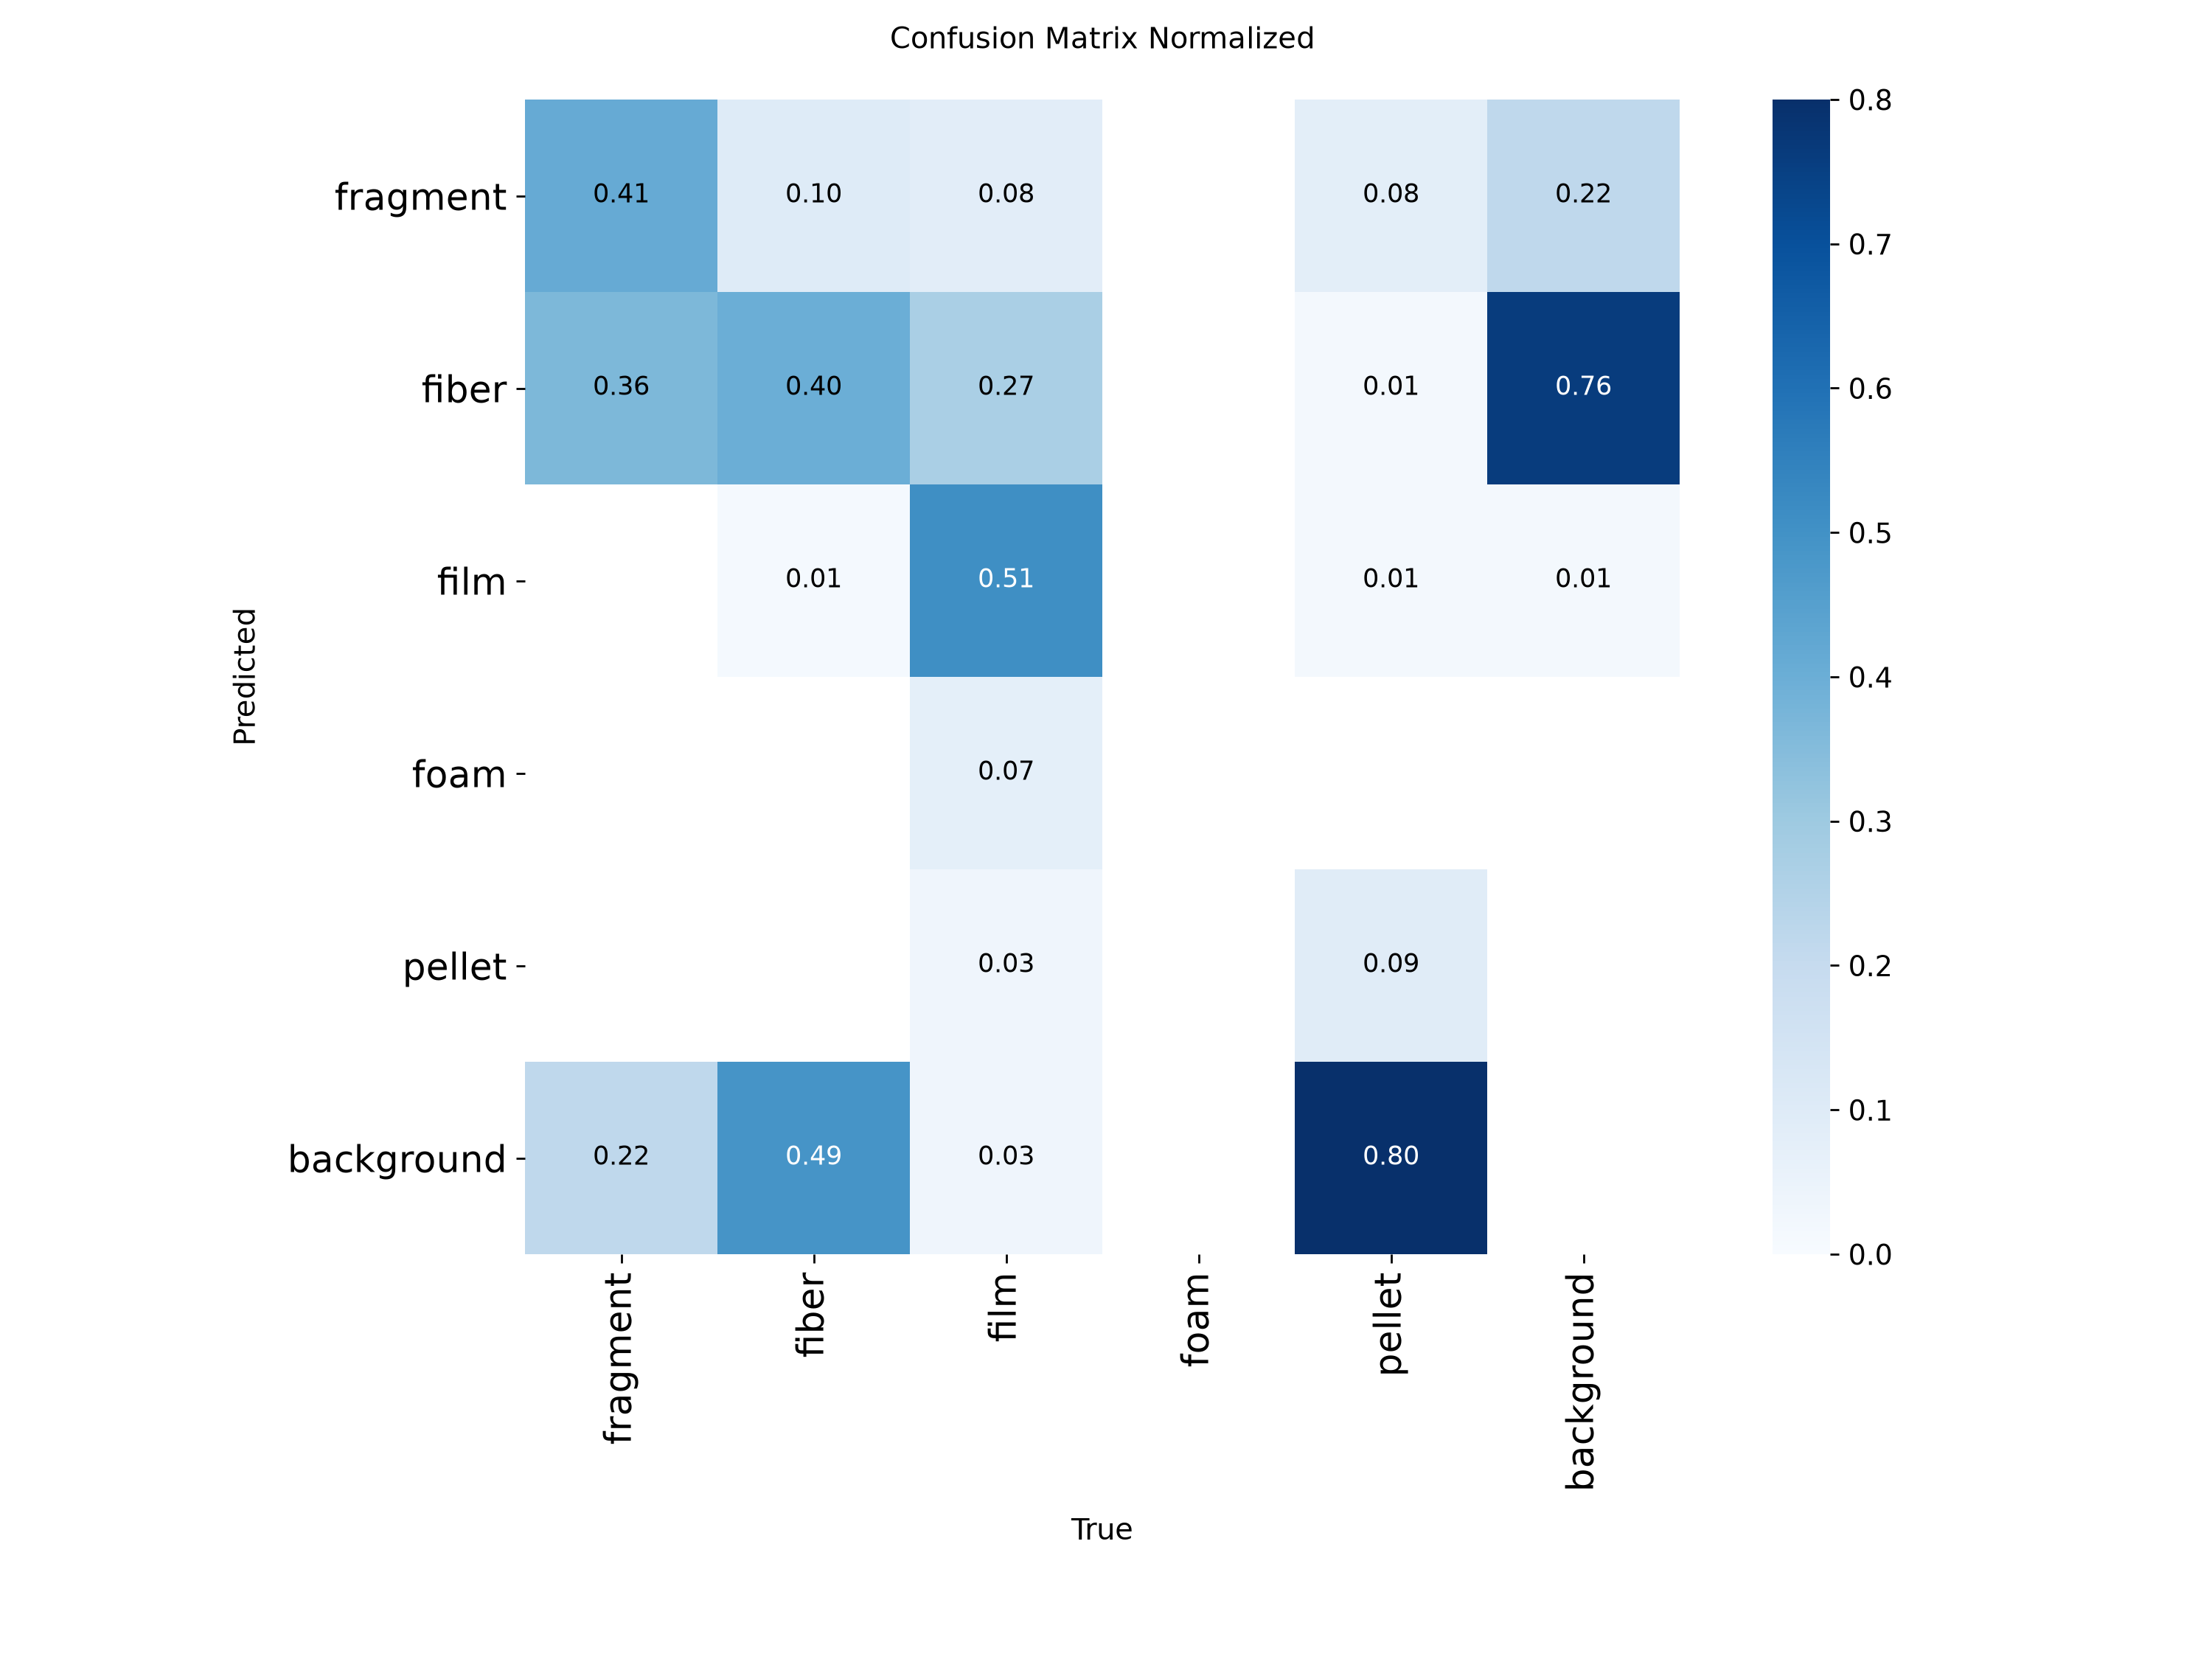

-- random --


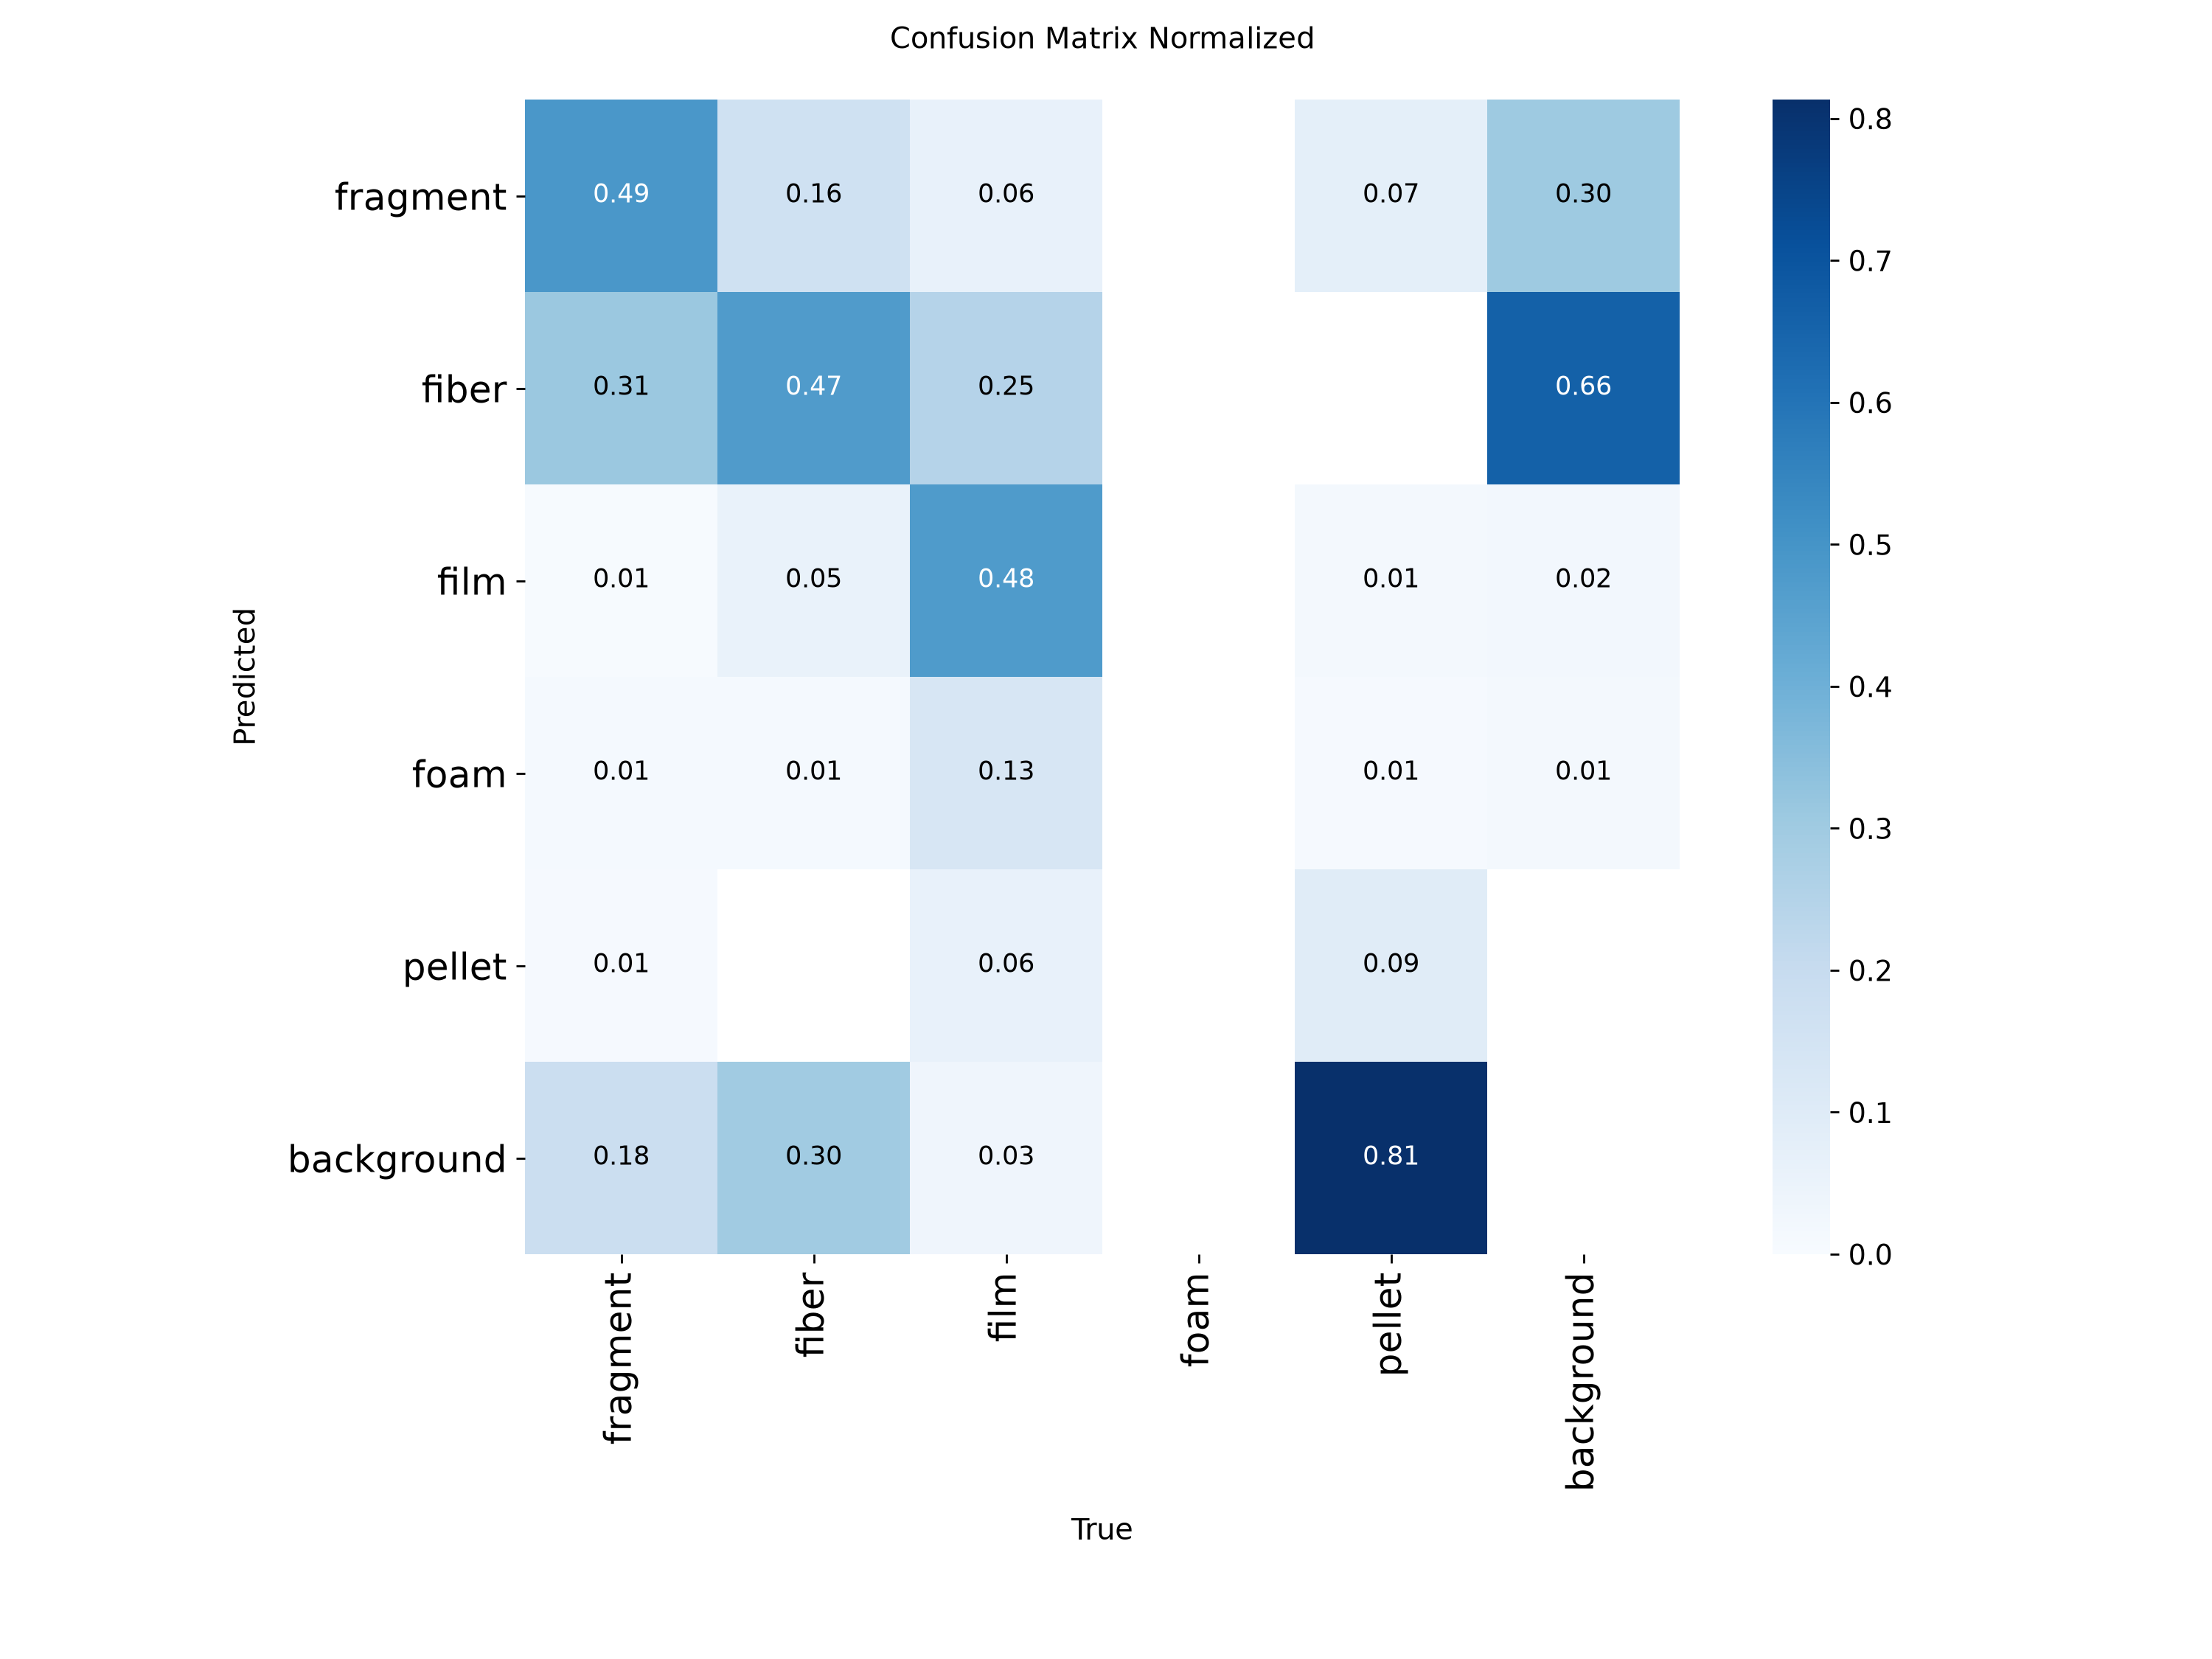

=== confusion matrices: clean (before = original, after = fine-tuned) ===
-- original --


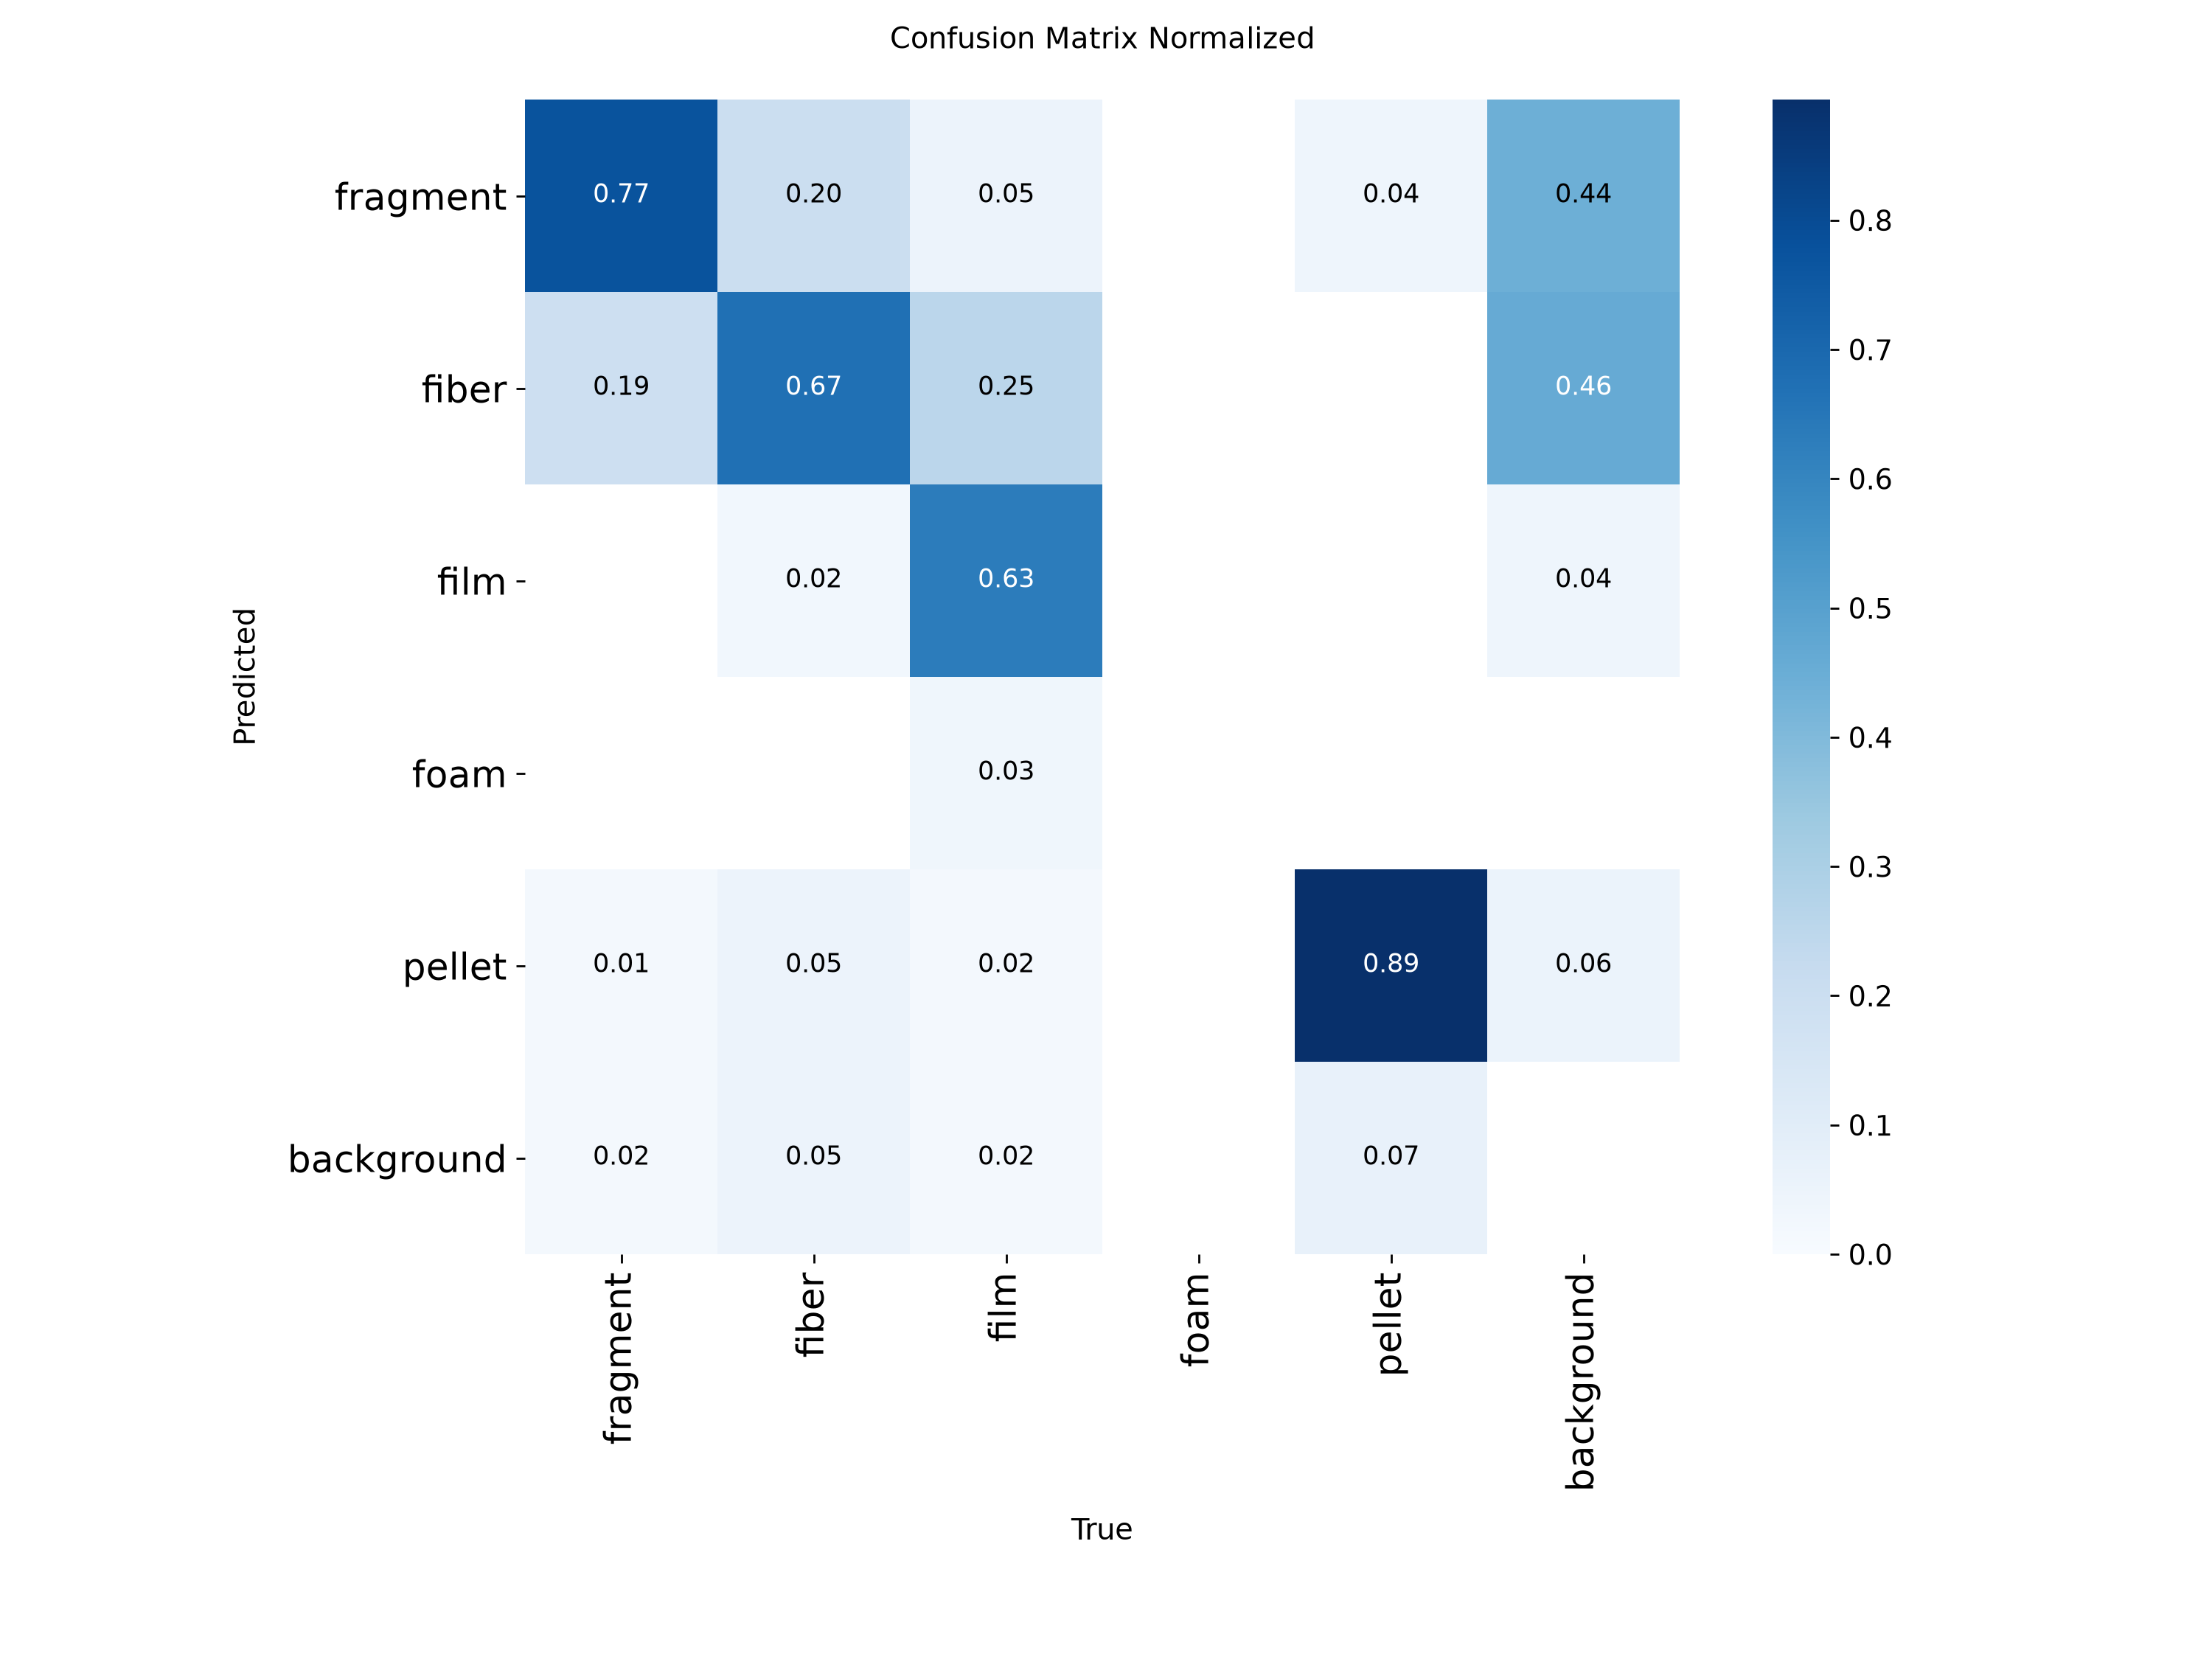

-- uncertainty --


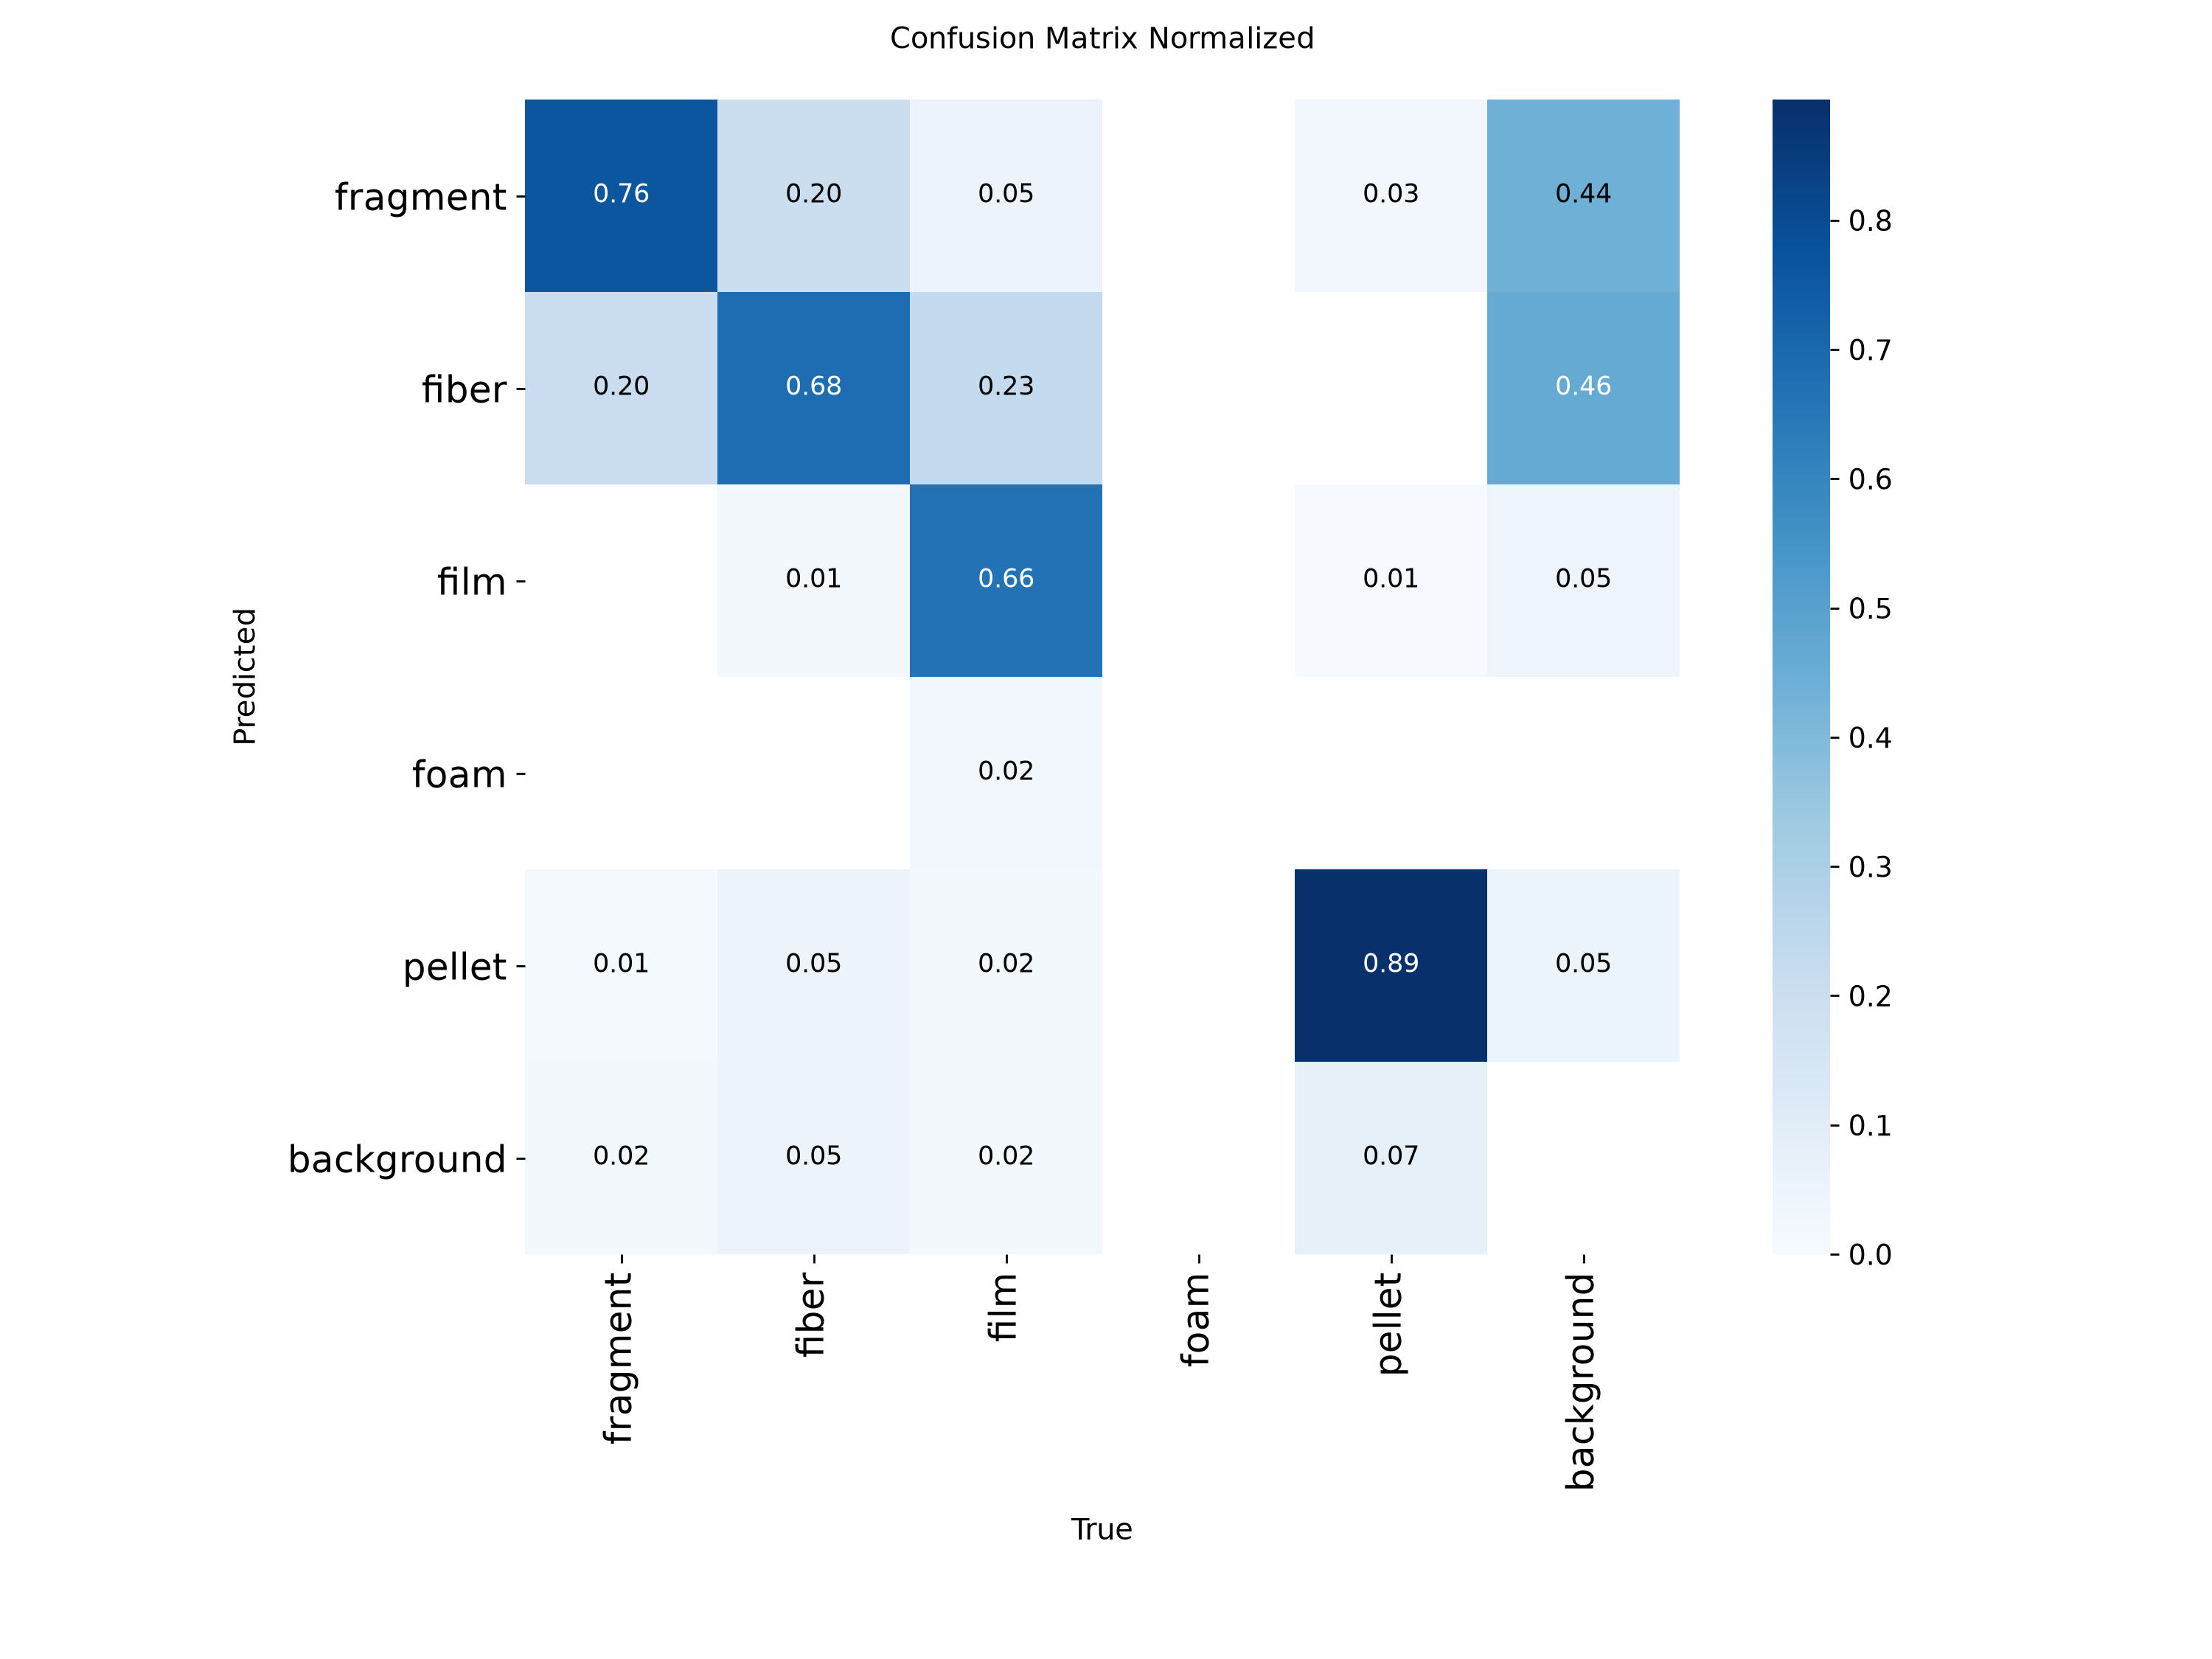

-- random --


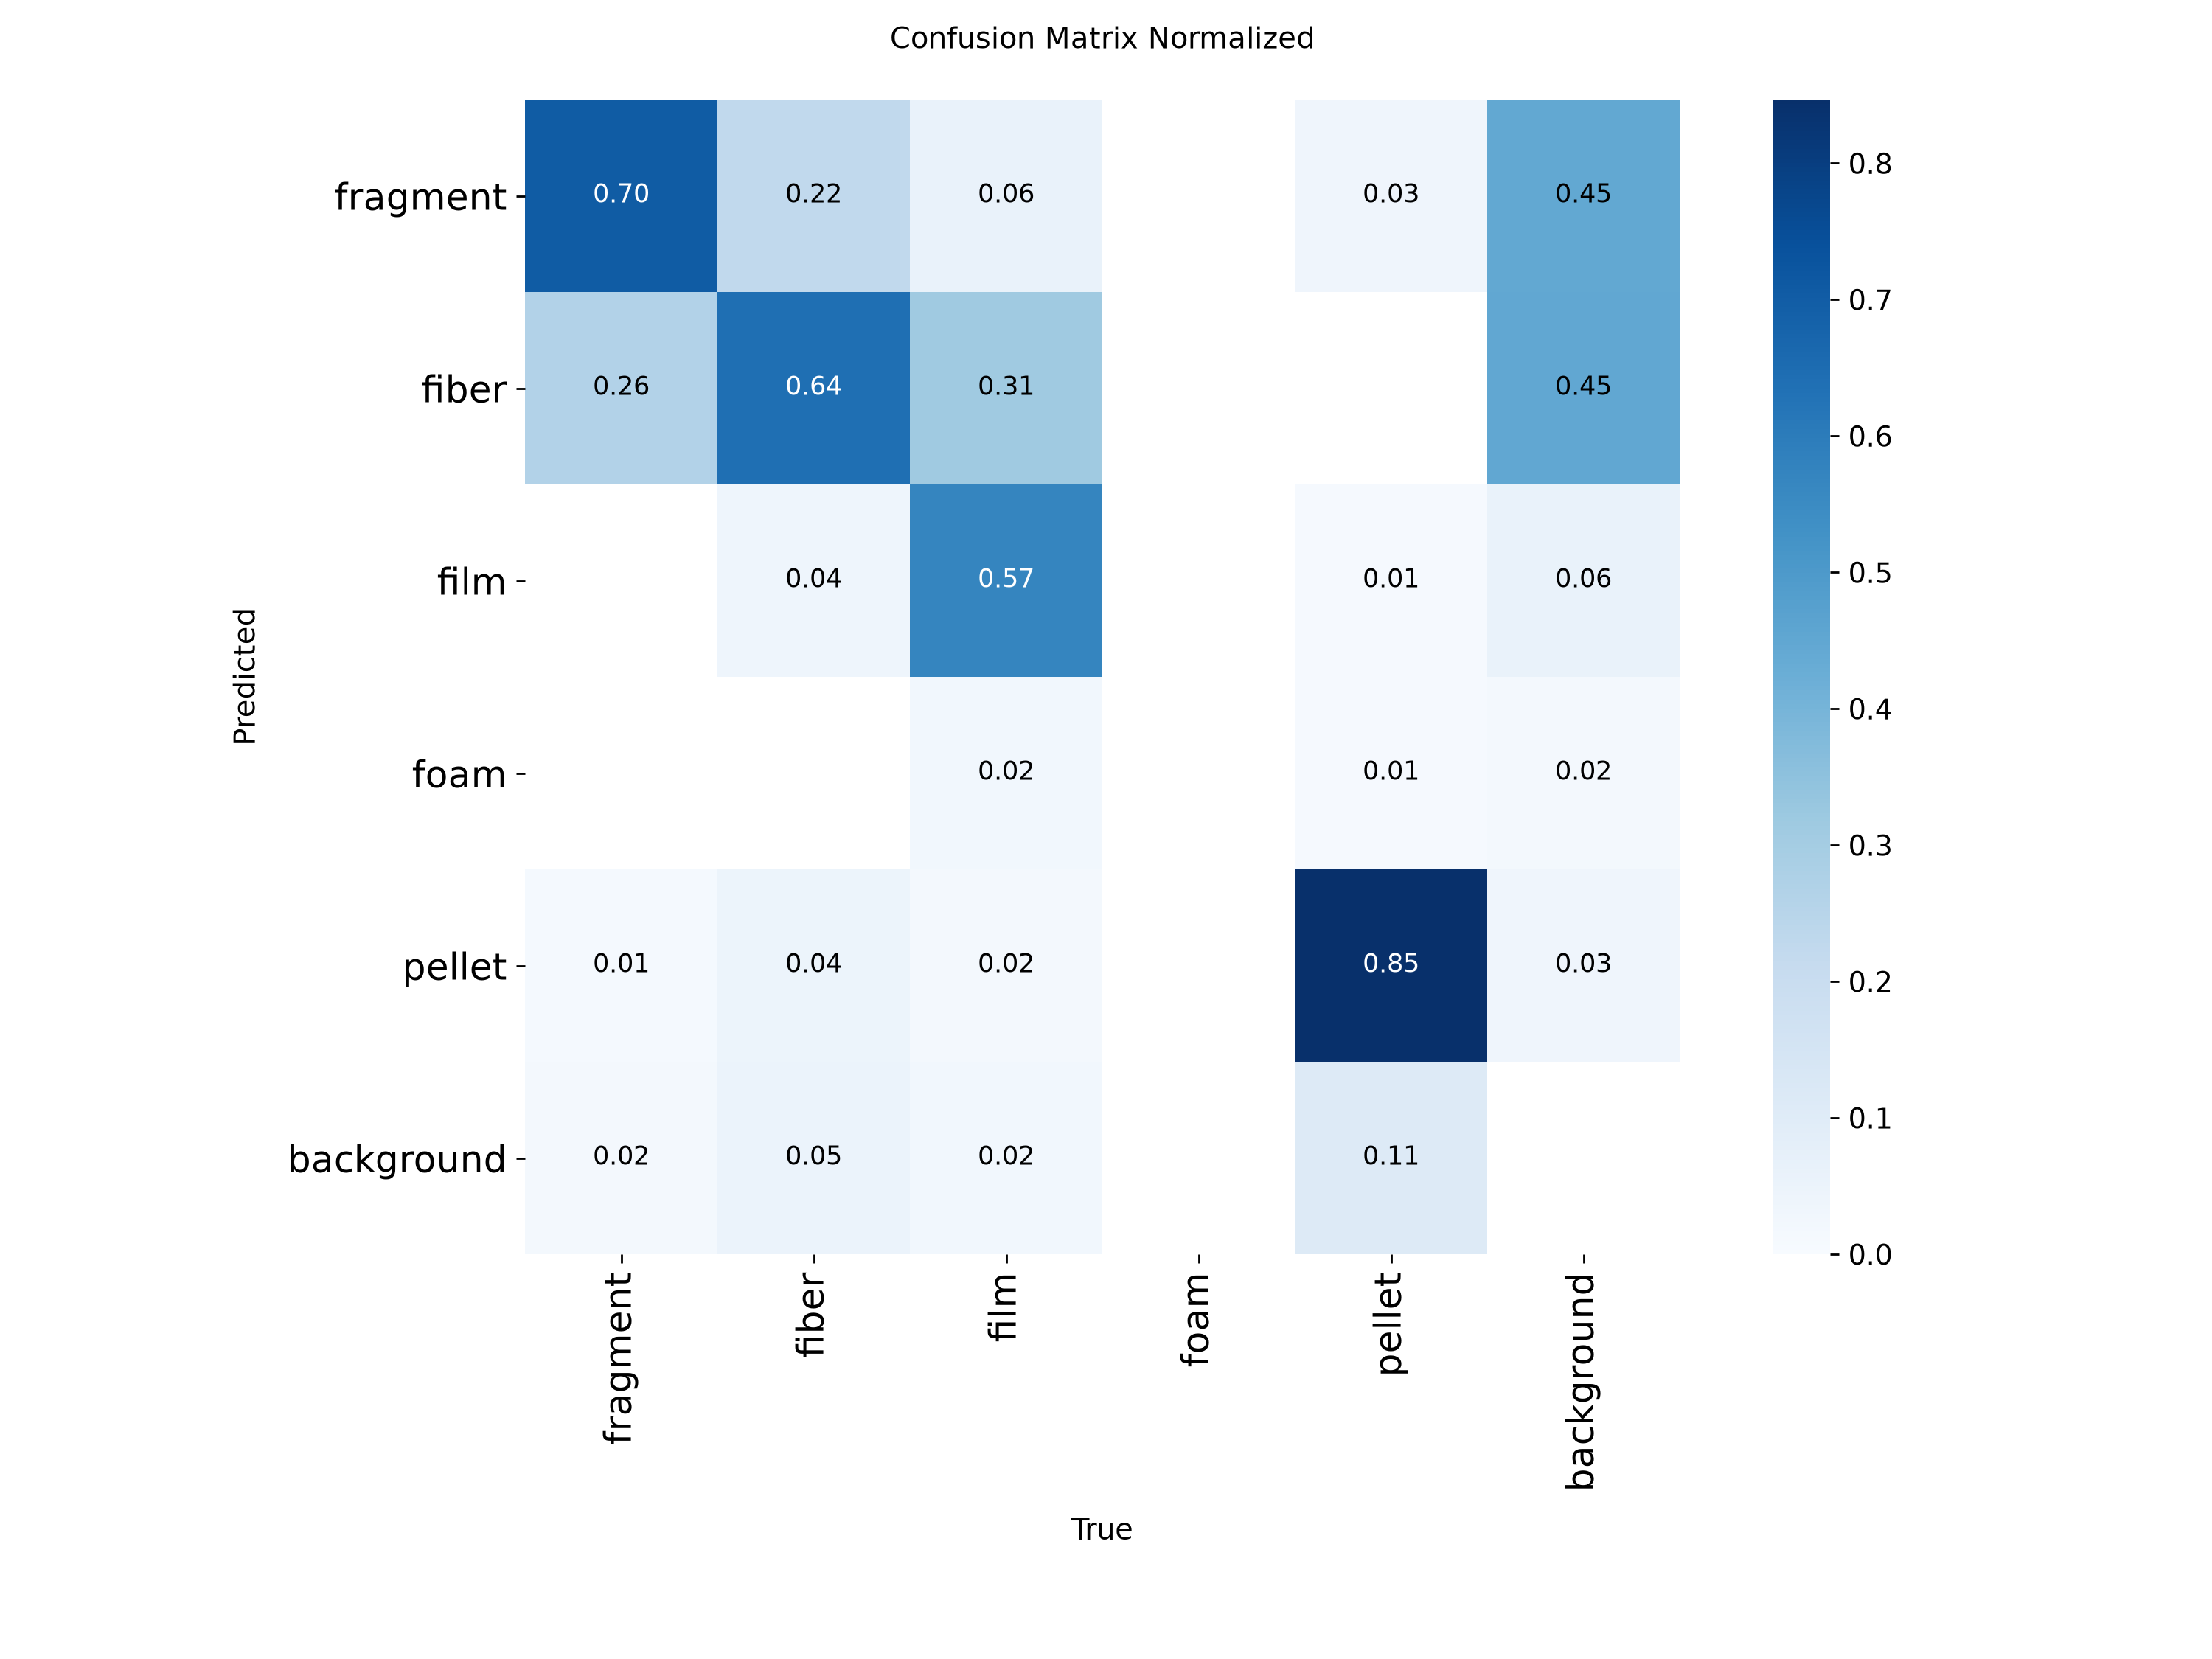

In [2]:
from IPython.display import Image

fig = OUT / 'figures'
for cond in ('turbid', 'clean'):
    print(f'=== confusion matrices: {cond} (before = original, after = fine-tuned) ===')
    for method in ('original', 'uncertainty', 'random'):
        print(f'-- {method} --')
        display(Image(filename=str(fig / f'cm_{method}_{cond}.png'), width=400))

## Findings

| | turbid ΔmAP50 | clean ΔmAP50 (retention) |
|---|---|---|
| **uncertainty** | **+0.0003** | **−0.0013** (no forgetting) |
| random | −0.0147 | −0.0309 (forgetting) |

- The original model collapses under turbidity (mAP50 0.837 → 0.319; fiber 0.16, pellet 0.14) — a real domain shift.
- **Uncertainty acquisition beats random at the same budget on both criteria**: it matches/slightly improves the
  unseen condition and fully retains clean performance, while random fine-tuning degrades both.
- Absolute turbid gains are small at B = 50 / 15 epochs — next levers are real turbid labels or B ≥ 200.
- `models/best.pt` was never written; the live demo is unaffected.